In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Import les données
df = pd.read_csv('data/Car_data.csv')

In [3]:
# Afficher les infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   str    
 3   Seller_Type    5861 non-null   str    
 4   Transmission   5861 non-null   str    
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 437.8 KB


### <font color = 'bisque'>Exploration et préparation des données

In [4]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(include = 'number')
quant_data.head()

,Kms_Driven,Present_Price,Age,Selling_Price
0,27000,5.59,6,3.35
1,43000,9.54,7,4.75
2,6900,9.85,3,7.25
3,5200,4.15,9,2.85
4,42450,6.87,6,4.60


In [5]:
# décrire les variables quantitatives
quant_data.describe()

,Kms_Driven,Present_Price,Age,Selling_Price
count,5861.000000,5861.000000,5861.000000,5861.000000
mean,75209.206108,16.869948,8.562532,10.196217
std,39198.500980,9.659501,3.099993,5.874282
min,500.000000,0.320000,2.000000,0.100000
25%,53822.000000,10.552438,6.000000,6.401756
50%,71822.000000,15.375776,8.000000,9.049277
75%,87820.000000,19.229938,10.000000,11.873727
max,538824.000000,102.661886,22.000000,41.903189


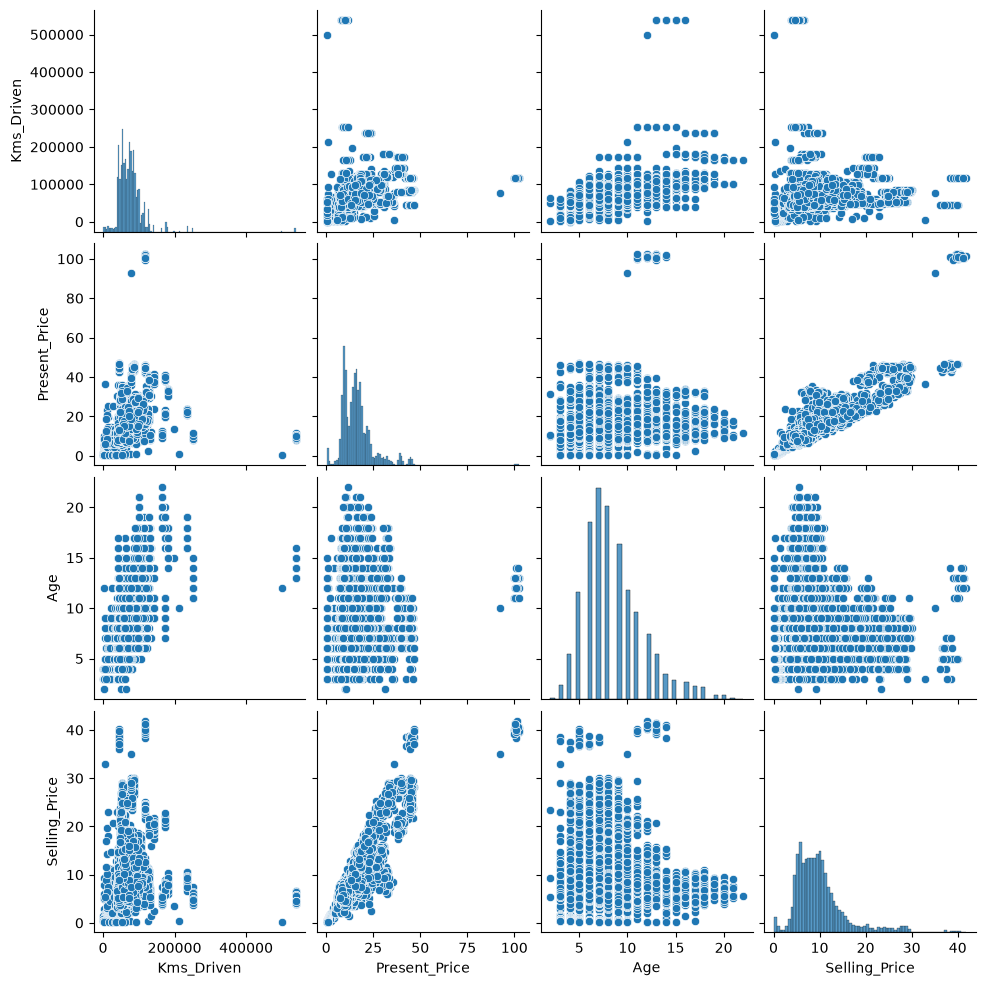

In [6]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [7]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df,x = col)
    fig.show()

In [8]:
# Appliquer la fonctions boxplot_func
for col in quant_data.columns:
  boxplot_func(col)

In [9]:
# Afficher la matrice de corrélation
quant_data.corr()

,Kms_Driven,Present_Price,Age,Selling_Price
Kms_Driven,1.000000,0.249279,0.527629,0.065816
Present_Price,0.249279,1.000000,0.073940,0.870457
Age,0.527629,0.073940,1.000000,-0.188531
Selling_Price,0.065816,0.870457,-0.188531,1.000000


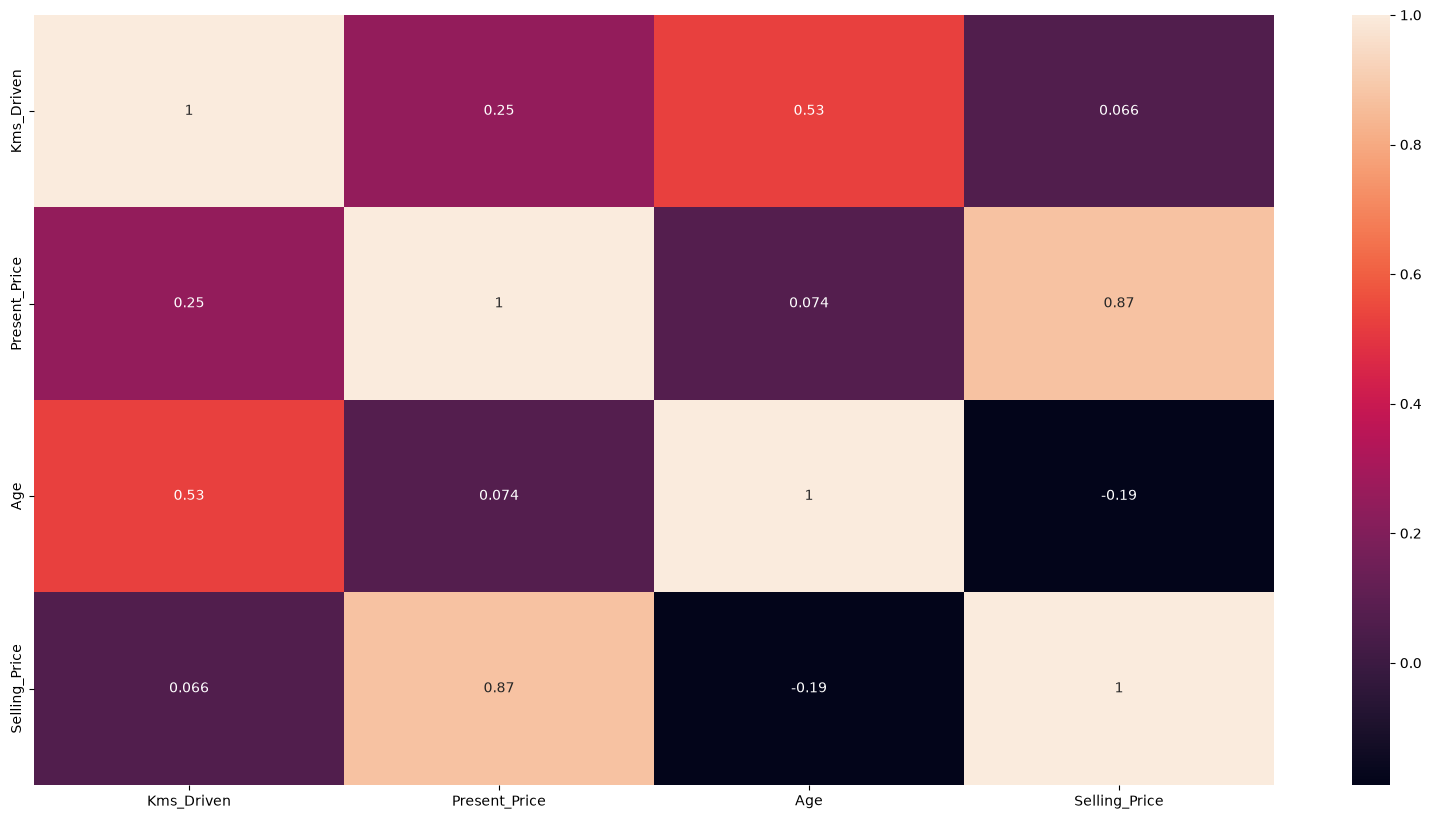

In [10]:
# Visualisaton le matrice de corrélation
plt.figure(figsize = (20, 10))
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [11]:
# sélection les variables catégorielles
cat_data = df.select_dtypes(include = 'object')

/var/folders/h6/6r86lwb103b38mcdv0c11jk40000gn/T/ipykernel_49992/2715263013.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_data = df.select_dtypes(include = 'object')


In [12]:
# Faire un describre
cat_data.describe()

,Fuel_Type,Seller_Type,Transmission
count,5861,5861,5861
unique,3,2,2
top,Petrol,Dealer,Automatic
freq,2743,3765,3007


In [13]:
# Fonction de visualisaion du counplot
def countplot_func(col):
    val = cat_data[col].value_counts()
    fig = px.bar(x = val.index, y = val.values,color = val.index.astype(str), text_auto = True)
    fig.show()

In [14]:
# Appliquer la fonction countplot_func
for col in cat_data.columns:
  countplot_func(col)

In [15]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoder0 = LabelEncoder()
encoder1 = LabelEncoder()
encoder2 = LabelEncoder()
encoders = [encoder0, encoder1, encoder2]
for i in range(len(cat_data.columns)):
  encoders[i].fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoders[i].transform(df[cat_data.columns[i]]) # encoder les valeurs

# valeurs uniques de chaque variable catégorielle (classes des encodeurs), utilisées pour les menus déroulants de l'application
uniques = [encoder.classes_.tolist() for encoder in encoders]

In [16]:
# télécharger les encodeurs et les valeurs uniques en utilisant joblib
import joblib
joblib.dump(encoders, 'models/encoders.joblib')
joblib.dump(uniques, 'models/uniques.joblib')

['models/uniques.joblib']

In [17]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [18]:
# Application du traitement
for col in quant_data.columns:
  impute_func(df,col)

In [19]:
# réafficher les boxplots
for col in quant_data.columns:
  boxplot_func(col)

In [20]:
# Fractionner les données
feature_cols = df.columns[:-1].tolist() # ordre des colonnes attendu par le modèle à l'inférence
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [21]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

In [22]:
from sklearn.preprocessing import RobustScaler
# Normaliser les variables numériques (ajustement sur le train uniquement pour éviter la fuite de données)
scaler = RobustScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

### <font color = 'bisque'>Random Forest Regressor<font>

In [23]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Dictionnaire des paramètres
param_grid = {
    'n_estimators': np.arange(10, 100, 10),
    'max_depth': np.arange(1, 15)
}

# Objet grid
grid_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

In [24]:
# paramètres optimaux
print(grid_rf.best_params_)

{'max_depth': np.int64(14), 'n_estimators': np.int64(80)}


In [25]:
# récupérer le meilleur modèle (ré-entraîné automatiquement par GridSearchCV avec refit=True)
best_rf = grid_rf.best_estimator_

In [26]:
# Barplot des contributions des variables
def bar_feat_imp(model):
  fig = px.bar(x = model.feature_importances_, y = feature_cols)
  fig.show()

In [27]:
# barplot
bar_feat_imp(best_rf)

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [28]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
# fonction de calcul du R2 score, Mean Squarred Error et Mean Absolute Error
def evaluation(model):
  y_pred = model.predict(x_val)
  # mse
  mse = mean_squared_error(y_val, y_pred)
  # r2
  r2 = r2_score(y_val, y_pred)
  # mae
  mae = mean_absolute_error(y_val, y_pred)
  return mse, r2, mae

In [29]:
# evaluation
mse_rf, r2_rf, mae_rf = evaluation(best_rf)
print(f"MSE : {mse_rf:.2f} -- R2 : {r2_rf:.2f} -- MAE : {mae_rf:.2f}")

MSE : 1.63 -- R2 : 0.88 -- MAE : 0.96


In [30]:
# Calculer le R2 score sur les données d'entrainement
y_pred_train = best_rf.predict(x_train)
print(f"R2 sur les données train : {r2_score(y_train, y_pred_train):.2f}")

R2 sur les données train : 0.96


### <font color = 'bisque'>XGBoost Regressor

In [31]:
# Rechercher les paramètres optimaux de l'algorithme
from xgboost import XGBRegressor
# Dictionnaire des paramètres
param_grid_xgb = {
    'n_estimators': np.arange(10, 100, 10),
    'max_depth': np.arange(1, 15)
}

# Objet grid
grid_xgb = GridSearchCV(XGBRegressor(random_state=42), param_grid_xgb, cv=5)
# Lancer la recherche
grid_xgb.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

In [32]:
# Afficher les paramètres optimaux
print(grid_xgb.best_params_)

{'max_depth': np.int64(5), 'n_estimators': np.int64(80)}


In [33]:
# récupérer le meilleur modèle (ré-entraîné automatiquement par GridSearchCV avec refit=True)
best_xgb = grid_xgb.best_estimator_

In [34]:
# Barplot des contributions des variables
bar_feat_imp(best_xgb)

#### <font color = 'teal'> Evaluation du XGBoost Regressor<font>

In [35]:
# Evaluation
mse_xgb, r2_xgb, mae_xgb = evaluation(best_xgb)
print(f"MSE : {mse_xgb:.2f} -- R2 : {r2_xgb:.2f} -- MAE : {mae_xgb:.2f}")

MSE : 1.69 -- R2 : 0.87 -- MAE : 0.99


In [36]:
# Calculer le R2 score sur les données d'entrainement
y_pred_train_xgb = best_xgb.predict(x_train)
print(f"R2 sur les données train : {r2_score(y_train, y_pred_train_xgb):.2f}")

R2 sur les données train : 0.94


In [37]:
# Comparer les deux modèles et sélectionner le plus performant
if r2_rf >= r2_xgb:
    best_model, model_name = best_rf, 'random_forest'
else:
    best_model, model_name = best_xgb, 'xgboost'
print(f"Modèle retenu : {model_name} (R2 = {max(r2_rf, r2_xgb):.2f})")

# télécharger le modèle le plus performant ainsi que les artefacts nécessaires à l'application
joblib.dump(best_model, 'models/model.joblib')
joblib.dump(model_name, 'models/model_name.joblib')
joblib.dump(scaler, 'models/scaler.joblib')
joblib.dump(feature_cols, 'models/feature_cols.joblib')

Modèle retenu : random_forest (R2 = 0.88)


['models/feature_cols.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [38]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = best_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"La voiture {i + 1} est vendue à {y_pred_10[i]:.2f} lakhs -- réel : {y_test_10[i]:.2f} lakhs")

La voiture 1 est vendue à 12.49 lakhs -- réel : 12.51 lakhs
La voiture 2 est vendue à 5.42 lakhs -- réel : 7.25 lakhs
La voiture 3 est vendue à 12.17 lakhs -- réel : 8.38 lakhs
La voiture 4 est vendue à 6.79 lakhs -- réel : 5.59 lakhs
La voiture 5 est vendue à 7.34 lakhs -- réel : 7.61 lakhs
La voiture 6 est vendue à 8.43 lakhs -- réel : 8.39 lakhs
La voiture 7 est vendue à 5.39 lakhs -- réel : 4.93 lakhs
La voiture 8 est vendue à 5.43 lakhs -- réel : 4.79 lakhs
La voiture 9 est vendue à 4.59 lakhs -- réel : 4.65 lakhs
La voiture 10 est vendue à 9.12 lakhs -- réel : 8.96 lakhs
